# 2D U(2) JAX Eval: CPU vs GPU

Wall-clock comparison of production JAX FT-HMC inference on **one NVIDIA A100 40 GB** versus **one Sophia CPU node**. Protocol matches [`2du2_bottleneck.ipynb`](2du2_bottleneck.ipynb): compile the Omelyan `metropolis_step`, time 32 steady steps plus the run-loop extras, then project to 200 therm + 2048 configs.

This is a **timing** study, not a physics chain. L=32 and L=64 load the L16 `base` checkpoint when no native npz exists; CNN weights are lattice-independent.

**Result (baseline, unjitted extras).** Through $64^2$, GPU production time is flat (~3.8 h for 2048 configs). The compiled FT step stays ~1.3 s; unjitted Python extras stay ~4.5 s and set the GPU total. The CPU compiled step scales with volume ($3.93\to 16.4\to 72.6$ s, ~$4\times$ per doubling), so the GPU advantage grows with $L$ only because the CPU gets slower.

**Result (jitted extras).** Production therm/run extras (`forward` + plaquette, and $Q$ in the run phase) are now `jax.jit`'d in `HMCU2FT` / `HMCU1FT`. Inverse is unchanged. The last section compares GPU `dump_suffix=jitobs` profiles at L16/L32/L64 against the baseline dumps above. If extras collapse, the GPU loop should sit near the compiled FT step (~1.3 s) and the 2048-config projection near **0.9 h**.

**Hardware.** Sophia compute nodes are NVIDIA DGX A100 boxes. `by-node` `select=1` is the whole box, not an unnamed CPU partition.

| Side | PBS | Processor | Cores used | Host RAM | Notes |
|---|---|---|---|---|---|
| GPU | `by-gpu` `ngpus=1` | 1× NVIDIA A100 40 GB | GPU only; CPU threads pinned to 1 | share of the node | production eval path |
| CPU | `by-node` `select=1` | **2× AMD EPYC 7742** (Rome), 64 cores/socket | **128 physical cores** (`OMP_NUM_THREADS=128`); not 256 SMT threads | **~1 TB DDR4** (24 nodes × ~1 TB = 26 TB cluster RAM) | one JAX CPU device, intra-op threads only |

CPU jobs live in [`2du2/evaluation/base_cpu/`](../2du2/evaluation/base_cpu/). GPU profiles live in [`2du2_bottleneck/dumps/`](2du2_bottleneck/dumps/). Plots go to [`2du2_cpu_gpu/plots/`](2du2_cpu_gpu/plots/). The next cell overwrites the table with measured `lscpu` / dump values when those files exist.

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

cwd = Path.cwd()
REPO_ROOT = cwd if (cwd / "2du2").exists() else cwd.parent
sys.path.insert(0, str(REPO_ROOT / "src"))

from nthmc.core.plot_settings import color_ls, default_plot, fs_p, fs_small_p

BETA = 10.0
TRAIN_BETA = 10.0
N_STEPS = 10
N_CONFIGS = 2048
N_THERM = 200
SEED = 1107
MODEL_TAG = "base"
WEIGHT_SAVE_TAG = f"{MODEL_TAG}_train_b{TRAIN_BETA:.1f}_L16_{SEED}"
LATTICES = (16, 32, 64)
DEVICES = ("gpu", "cpu")
KERNEL_ORDER = ["cnn_apply", "forward", "jac_logdet", "new_action", "force", "fthmc_step", "hmc_force", "hmc_step"]
KERNEL_LABELS = {
    "cnn_apply": "CNN (1 subset)",
    "forward": "forward (8 subsets)",
    "jac_logdet": r"$\log|J|$",
    "new_action": "new action",
    "force": r"$\nabla$ new action",
    "fthmc_step": "FT-HMC step",
    "hmc_force": "Wilson force",
    "hmc_step": "HMC step",
}
STEP_KEYS = [
    ("compile", "FT compile"),
    ("steady", r"FT step"),
    ("extras", "Python extras"),
    ("hmc", "HMC step"),
]
GPU_LABEL = "GPU 1×A100 40 GB"
CPU_LABEL = "CPU 2×EPYC 7742 (128 cores)"
A100_FP32_GFLOPS = 19.5e3  # advertised FP32 peak, A100 40 GB
A100_HBM_GBS = 1555.0

GPU_DUMP_DIR = REPO_ROOT / "presentation" / "2du2_bottleneck" / "dumps"
CPU_DUMP_DIR = REPO_ROOT / "2du2" / "evaluation" / "base_cpu" / "dumps"
CPU_LOG_DIR = REPO_ROOT / "2du2" / "evaluation" / "base_cpu" / "logs"
PLOT_DIR = REPO_ROOT / "presentation" / "2du2_cpu_gpu" / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# ALCF Sophia compute node: NVIDIA DGX A100.
# https://www.alcf.anl.gov/sophia  (26 TB DDR4 / 24 nodes ≈ 1 TB/node)
SOPHIA_CPU = {
    "cpu_model": "AMD EPYC 7742 64-Core Processor",
    "sockets": "2",
    "cores_per_socket": "64",
    "physical_cores": 128,
    "logical_cpus": "256",
    "threads_per_core": "2",
    "mem_total_kb": 1024 * 1024 * 1024,  # documented ~1 TB
}


def dump_candidates(lattice, device, suffix=""):
    stem = f"inference_profile_L{lattice}_beta{BETA:.1f}_nsteps{N_STEPS}_{WEIGHT_SAVE_TAG}"
    if suffix:
        stem = f"{stem}_{suffix}"
    tagged = f"{stem}_{device}.json"
    if device == "gpu" and not suffix:
        return [GPU_DUMP_DIR / tagged, GPU_DUMP_DIR / f"{stem}.json"]
    if device == "gpu":
        return [GPU_DUMP_DIR / tagged]
    return [CPU_DUMP_DIR / tagged]


def cpu_log_path(lattice):
    return CPU_LOG_DIR / (
        f"profile_cpu_{MODEL_TAG}_L{lattice}_train_b{TRAIN_BETA:.1f}_eval_b{BETA:.1f}_{SEED}.log"
    )


def load_dump(lattice, device, suffix=""):
    for path in dump_candidates(lattice, device, suffix):
        if path.exists():
            payload = json.loads(path.read_text())
            payload["_path"] = str(path)
            return payload
    return None


def fmt(value, spec=".3f"):
    if value is None:
        return "—"
    return format(value, spec)


def lscpu_field(text, key):
    prefix = f"{key}:"
    for line in text.splitlines():
        if line.startswith(prefix):
            value = line.split(":", 1)[1].strip()
            return value or None
    return None


def parse_cpu_log(lattice):
    path = cpu_log_path(lattice)
    if not path.exists():
        return None
    text = path.read_text(errors="replace")
    sockets = lscpu_field(text, "Socket(s)")
    cores_per_socket = lscpu_field(text, "Core(s) per socket")
    physical = None
    if sockets and cores_per_socket:
        try:
            physical = int(sockets) * int(cores_per_socket)
        except ValueError:
            physical = None
    match = re.search(r"Using (\d+) physical CPU threads", text)
    mem_kb = None
    mem_match = re.search(r"^MemTotal:\s+(\d+)\s+kB", text, re.MULTILINE)
    if mem_match:
        mem_kb = int(mem_match.group(1))
    else:
        free_match = re.search(r"^Mem:\s+([0-9.]+)(Ti|Gi|T|G)\b", text, re.MULTILINE | re.IGNORECASE)
        if free_match:
            value = float(free_match.group(1))
            unit = free_match.group(2).lower()
            mem_kb = int(value * (1024 ** 3 if unit.startswith("t") else 1024 ** 2))
    return {
        "cpu_model": lscpu_field(text, "Model name"),
        "sockets": sockets,
        "cores_per_socket": cores_per_socket,
        "threads_per_core": lscpu_field(text, "Thread(s) per core"),
        "logical_cpus": lscpu_field(text, "CPU(s)"),
        "physical_cores": physical,
        "omp_num_threads": match.group(1) if match else None,
        "mem_total_kb": mem_kb,
        "_source": str(path),
    }


def mem_str(mem_kb):
    if not mem_kb:
        return None
    gib = mem_kb / (1024.0 ** 2)
    if gib >= 900:
        return f"{gib / 1024.0:.2f} TB ({gib:.0f} GiB)"
    return f"{gib:.0f} GiB"


def host_fields(dump):
    return ((dump or {}).get("config") or {}).get("host") or {}


def _filled(value):
    return value not in (None, "")


def measured_cpu():
    merged = {}
    sources = []
    for lattice in LATTICES:
        dump = dumps[(lattice, "cpu")]
        host = dict(host_fields(dump))
        if dump is not None and host:
            for key, value in host.items():
                if _filled(value) and not _filled(merged.get(key)):
                    merged[key] = value
            sources.append(dump["_path"])
        log_info = parse_cpu_log(lattice)
        if not log_info:
            continue
        for key, value in log_info.items():
            if key == "_source" or not _filled(value) or _filled(merged.get(key)):
                continue
            merged[key] = value
        if log_info.get("_source"):
            sources.append(log_info["_source"])
    if not merged:
        return None
    merged["_source"] = "; ".join(dict.fromkeys(sources))
    return merged


def host_line(dump, device):
    if device == "gpu":
        intended = "1× NVIDIA A100 40 GB"
    else:
        intended = "2× AMD EPYC 7742, 128 physical cores / 256 SMT, ~1 TB RAM"
    if dump is None:
        return f"dump missing; intended {intended}"
    cfg = dump.get("config") or {}
    host = cfg.get("host") or {}
    backend = cfg.get("jax_backend") or cfg.get("device")
    devices = ", ".join(cfg.get("jax_devices") or [])
    if device == "gpu":
        return f"{intended}; JAX {backend}; devices=[{devices}]"
    merged = {**SOPHIA_CPU, **{k: v for k, v in host.items() if _filled(v)}}
    model = merged.get("cpu_model")
    physical = merged.get("physical_cores")
    sockets = merged.get("sockets")
    per_socket = merged.get("cores_per_socket")
    logical = merged.get("logical_cpus") or merged.get("nproc")
    omp = merged.get("omp_num_threads") or physical
    mem = mem_str(merged.get("mem_total_kb")) or "~1 TB"
    hostname = merged.get("hostname") or "—"
    return (
        f"{model}; {sockets}×{per_socket} = {physical} physical cores, "
        f"{logical} SMT; JAX/OMP={omp}; RAM={mem}; host={hostname}"
    )


def wall(dump):
    if dump is None:
        return {"compile": None, "steady": None, "extras": None, "hmc": None, "loop": None, "projected_h": None}
    ft = dump["wall_clock"]["fthmc"]
    hmc = dump["wall_clock"]["hmc"]
    extras = (ft.get("run_observable_s") or {}).get("mean_s")
    projected = (dump.get("extrapolation") or {}).get("projected_total_s")
    return {
        "compile": ft.get("first_step_s"),
        "steady": ft.get("steady_mean_s"),
        "extras": extras,
        "hmc": hmc.get("steady_mean_s"),
        "loop": ft.get("python_loop_mean_s"),
        "projected_h": None if projected is None else projected / 3600.0,
    }


def kernel_mean(dump, name):
    if dump is None:
        return None
    item = (dump.get("kernels") or {}).get(name) or {}
    return item.get("mean_s")


def kernel_item(dump, name):
    if dump is None:
        return {}
    return (dump.get("kernels") or {}).get(name) or {}


def kernel_flops(dump, name):
    return (kernel_item(dump, name).get("cost") or {}).get("flops")


def kernel_bytes(dump, name):
    return (kernel_item(dump, name).get("cost") or {}).get("bytes_accessed")


def kernel_gflops(dump, name):
    flops = kernel_flops(dump, name)
    mean_s = kernel_mean(dump, name)
    if flops is None or mean_s in (None, 0):
        return None
    return flops / mean_s / 1e9


def kernel_gbs(dump, name):
    nbytes = kernel_bytes(dump, name)
    mean_s = kernel_mean(dump, name)
    if nbytes is None or mean_s in (None, 0):
        return None
    return nbytes / mean_s / 1e9


def pct_peak_fp32(gflops):
    if gflops is None:
        return None
    return 100.0 * gflops / A100_FP32_GFLOPS


def pct_peak_hbm(gbs):
    if gbs is None:
        return None
    return 100.0 * gbs / A100_HBM_GBS


def fmt_pct(value):
    if value is None:
        return "—"
    if value < 0.1:
        return f"{value:.3f}%"
    return f"{value:.2f}%"


def fmt_gflops(value):
    if value is None:
        return "—"
    if value >= 10:
        return f"{value:.1f}"
    if value >= 1:
        return f"{value:.2f}"
    return f"{value:.3f}"


dumps = {(lattice, device): load_dump(lattice, device) for lattice in LATTICES for device in DEVICES}
JITOBS_SUFFIX = "jitobs"
jitobs_dumps = {lattice: load_dump(lattice, "gpu", JITOBS_SUFFIX) for lattice in LATTICES}
cpu_hw = measured_cpu() or dict(SOPHIA_CPU)
cpu_source = (cpu_hw.get("_source") if cpu_hw else None) or "ALCF Sophia / DGX A100 documented spec"
status = [
    "## Dump status",
    "",
]
for lattice in LATTICES:
    for device in DEVICES:
        dump = dumps[(lattice, device)]
        if dump is None:
            paths = ", ".join(f"`{path}`" for path in dump_candidates(lattice, device))
            extra = ""
            if device == "cpu":
                extra = f"; log `{cpu_log_path(lattice)}`"
            status.append(f"- L={lattice} {device}: **missing** ({paths}{extra})")
        else:
            status.append(f"- L={lattice} {device}: `{dump['_path']}` — {host_line(dump, device)}")
status.append("")
status.append("## Jitted extras dumps (GPU only, `dump_suffix=jitobs`)")
status.append("")
for lattice in LATTICES:
    dump = jitobs_dumps[lattice]
    if dump is None:
        paths = ", ".join(f"`{path}`" for path in dump_candidates(lattice, "gpu", JITOBS_SUFFIX))
        status.append(f"- L={lattice} GPU jitobs: **missing** ({paths})")
    else:
        status.append(f"- L={lattice} GPU jitobs: `{dump['_path']}` — {host_line(dump, 'gpu')}")
status.extend(
    [
        "",
        "## CPU node (not just `by-node`)",
        "",
        "| field | value |",
        "|---|---|",
        f"| CPU | {cpu_hw.get('cpu_model') or SOPHIA_CPU['cpu_model']} |",
        f"| sockets × cores | {cpu_hw.get('sockets') or 2} × {cpu_hw.get('cores_per_socket') or 64} = "
        f"**{cpu_hw.get('physical_cores') or 128} physical cores** |",
        f"| SMT / `nproc` | {cpu_hw.get('logical_cpus') or cpu_hw.get('nproc') or 256} "
        f"(threads/core={cpu_hw.get('threads_per_core') or 2}); **not used** by JAX |",
        f"| JAX / OpenMP threads | {cpu_hw.get('omp_num_threads') or cpu_hw.get('physical_cores') or 128} |",
        f"| host RAM | {mem_str(cpu_hw.get('mem_total_kb')) or '~1 TB DDR4'} |",
        f"| source | `{cpu_source}` |",
        "",
        "GPU comparison is **1× NVIDIA A100 40 GB**, not the node's 8 GPUs. "
        "Baseline L16/L32/L64 dumps are the unjitted-extras profiles. "
        "`jitobs` dumps are GPU-only L16/L32/L64 after compiling therm/run extras.",
    ]
)
display(Markdown("\n".join(status)))


## Dump status

- L=16 gpu: `/lus/eagle/projects/fthmc/run/NTHMC/presentation/2du2_bottleneck/dumps/inference_profile_L16_beta10.0_nsteps10_base_train_b10.0_L16_1107.json` — 1× NVIDIA A100 40 GB; JAX gpu; devices=[cuda:0]
- L=16 cpu: `/lus/eagle/projects/fthmc/run/NTHMC/2du2/evaluation/base_cpu/dumps/inference_profile_L16_beta10.0_nsteps10_base_train_b10.0_L16_1107_cpu.json` — AMD EPYC 7742 64-Core Processor; 2×64 = 128 physical cores, 256 SMT; JAX/OMP=128; RAM=0.98 TB (1007 GiB); host=sophia-gpu-07
- L=32 gpu: `/lus/eagle/projects/fthmc/run/NTHMC/presentation/2du2_bottleneck/dumps/inference_profile_L32_beta10.0_nsteps10_base_train_b10.0_L16_1107_gpu.json` — 1× NVIDIA A100 40 GB; JAX gpu; devices=[cuda:0]
- L=32 cpu: `/lus/eagle/projects/fthmc/run/NTHMC/2du2/evaluation/base_cpu/dumps/inference_profile_L32_beta10.0_nsteps10_base_train_b10.0_L16_1107_cpu.json` — AMD EPYC 7742 64-Core Processor; 2×64 = 128 physical cores, 256 SMT; JAX/OMP=128; RAM=0.98 TB (1007 GiB); host=sophia-gpu-06
- L=64 gpu: `/lus/eagle/projects/fthmc/run/NTHMC/presentation/2du2_bottleneck/dumps/inference_profile_L64_beta10.0_nsteps10_base_train_b10.0_L16_1107_gpu.json` — 1× NVIDIA A100 40 GB; JAX gpu; devices=[cuda:0]
- L=64 cpu: `/lus/eagle/projects/fthmc/run/NTHMC/2du2/evaluation/base_cpu/dumps/inference_profile_L64_beta10.0_nsteps10_base_train_b10.0_L16_1107_cpu.json` — AMD EPYC 7742 64-Core Processor; 2×64 = 128 physical cores, 256 SMT; JAX/OMP=128; RAM=0.98 TB (1007 GiB); host=sophia-gpu-03

## Jitted extras dumps (GPU only, `dump_suffix=jitobs`)

- L=16 GPU jitobs: `/lus/eagle/projects/fthmc/run/NTHMC/presentation/2du2_bottleneck/dumps/inference_profile_L16_beta10.0_nsteps10_base_train_b10.0_L16_1107_jitobs_gpu.json` — 1× NVIDIA A100 40 GB; JAX gpu; devices=[cuda:0]
- L=32 GPU jitobs: `/lus/eagle/projects/fthmc/run/NTHMC/presentation/2du2_bottleneck/dumps/inference_profile_L32_beta10.0_nsteps10_base_train_b10.0_L16_1107_jitobs_gpu.json` — 1× NVIDIA A100 40 GB; JAX gpu; devices=[cuda:0]
- L=64 GPU jitobs: `/lus/eagle/projects/fthmc/run/NTHMC/presentation/2du2_bottleneck/dumps/inference_profile_L64_beta10.0_nsteps10_base_train_b10.0_L16_1107_jitobs_gpu.json` — 1× NVIDIA A100 40 GB; JAX gpu; devices=[cuda:0]

## CPU node (not just `by-node`)

| field | value |
|---|---|
| CPU | AMD EPYC 7742 64-Core Processor |
| sockets × cores | 2 × 64 = **128 physical cores** |
| SMT / `nproc` | 256 (threads/core=2); **not used** by JAX |
| JAX / OpenMP threads | 128 |
| host RAM | 0.98 TB (1007 GiB) |
| source | `/lus/eagle/projects/fthmc/run/NTHMC/2du2/evaluation/base_cpu/dumps/inference_profile_L16_beta10.0_nsteps10_base_train_b10.0_L16_1107_cpu.json; /lus/eagle/projects/fthmc/run/NTHMC/2du2/evaluation/base_cpu/logs/profile_cpu_base_L16_train_b10.0_eval_b10.0_1107.log; /lus/eagle/projects/fthmc/run/NTHMC/2du2/evaluation/base_cpu/dumps/inference_profile_L32_beta10.0_nsteps10_base_train_b10.0_L16_1107_cpu.json; /lus/eagle/projects/fthmc/run/NTHMC/2du2/evaluation/base_cpu/logs/profile_cpu_base_L32_train_b10.0_eval_b10.0_1107.log; /lus/eagle/projects/fthmc/run/NTHMC/2du2/evaluation/base_cpu/dumps/inference_profile_L64_beta10.0_nsteps10_base_train_b10.0_L16_1107_cpu.json; /lus/eagle/projects/fthmc/run/NTHMC/2du2/evaluation/base_cpu/logs/profile_cpu_base_L64_train_b10.0_eval_b10.0_1107.log` |

GPU comparison is **1× NVIDIA A100 40 GB**, not the node's 8 GPUs. Baseline L16/L32/L64 dumps are the unjitted-extras profiles. `jitobs` dumps are GPU-only L16/L32/L64 after compiling therm/run extras.

## Per-step wall time

Four numbers, all wall-clock seconds:

- **FT compile** is the first production `metropolis_step`. That call JIT-compiles the full Omelyan trajectory (`n_steps=10`).
- **FT step** is a later compiled `metropolis_step` (mean of 32). Sampler only; no observables.
- **Python extras** in these **baseline** dumps is the unjitted host work the eval loop does **after** each saved config: field transform `forward`, Wilson plaquette, and topological charge $Q$. It is not inside the compiled step. Thermalization skips $Q$; the column here is the **run-phase** extras (with $Q$). The last section repeats the same protocol after those extras are jitted.
- **HMC step** is the Wilson baseline `metropolis_step` on the same backend.

**Loop** = FT step + Python extras. That is the steady cost of one production config after compile.

**What the table shows.** GPU loop is $5.8$–$6.0$ s at every $L$. The compiled FT step is $1.420\to 1.347\to 1.276$ s (slightly *down*, std $\lesssim 0.5\%$). Python extras are $4.46$–$4.61$ s on GPU and $4.11$–$4.39$ s on CPU, so they dominate the GPU config and barely move with volume: the compiled `forward` AOT is only ~$4$–$5$ ms, and the extra ~$4.5$ s is unjitted dispatch plus `float()` host sync, not lattice FLOPs. CPU FT step is the volume-limited piece: $3.93\to 16.4\to 72.6$ s (~$4.2\times$ then ~$4.4\times$). Compile is a one-shot tax (~$8$ min GPU, ~$41$ min CPU) and does not grow with $L$. HMC is milliseconds; at L16 the GPU HMC step is slower than CPU ($5.1$ vs $2.9$ ms, launch overhead), and by L64 the CPU has scaled to $43$ ms while GPU stays ~$5$ ms.

## Compile, trajectory, Python extras, HMC

| L | device | FT compile / s | FT step / s | Python extras / s | HMC step / s | loop / s | projected 2048 / h |
|---:|---|---:|---:|---:|---:|---:|---:|
| 16 | gpu | 488.4 | 1.4200 | 4.5581 | 0.0051 | 5.9782 | 3.88 |
| 16 | cpu | 2492.5 | 3.9257 | 4.1104 | 0.0029 | 8.0361 | 5.71 |
| 32 | gpu | 508.5 | 1.3466 | 4.4607 | 0.0054 | 5.8074 | 3.78 |
| 32 | cpu | 2437.9 | 16.4166 | 4.1396 | 0.0104 | 20.5562 | 13.50 |
| 64 | gpu | 527.0 | 1.2756 | 4.6098 | 0.0048 | 5.8854 | 3.84 |
| 64 | cpu | 2441.6 | 72.5683 | 4.3871 | 0.0428 | 76.9553 | 48.72 |

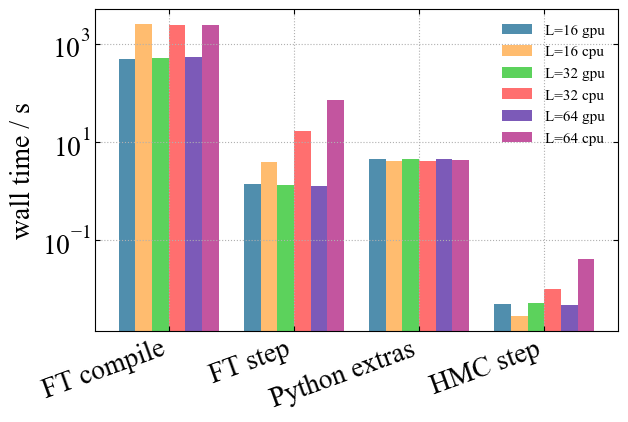

In [2]:
lines = ["## Compile, trajectory, Python extras, HMC", "", "| L | device | FT compile / s | FT step / s | Python extras / s | HMC step / s | loop / s | projected 2048 / h |", "|---:|---|---:|---:|---:|---:|---:|---:|"]
for lattice in LATTICES:
    for device in DEVICES:
        row = wall(dumps[(lattice, device)])
        lines.append(
            f"| {lattice} | {device} | {fmt(row['compile'], '.1f')} | {fmt(row['steady'], '.4f')} | "
            f"{fmt(row['extras'], '.4f')} | {fmt(row['hmc'], '.4f')} | {fmt(row['loop'], '.4f')} | {fmt(row['projected_h'], '.2f')} |"
        )
display(Markdown("\n".join(lines)))

ready = [dumps[(lattice, device)] is not None for lattice in LATTICES for device in DEVICES]
if any(ready):
    labels = [label for _, label in STEP_KEYS]
    x = np.arange(len(labels))
    n_series = len(LATTICES) * len(DEVICES)
    width = 0.8 / n_series
    fig, ax = default_plot()
    offset = -0.5 * (n_series - 1) * width
    color_i = 0
    for lattice in LATTICES:
        for device in DEVICES:
            row = wall(dumps[(lattice, device)])
            values = [row[key] if row[key] is not None else np.nan for key, _ in STEP_KEYS]
            ax.bar(x + offset, values, width=width, label=f"L={lattice} {device}", color=color_ls[color_i])
            offset += width
            color_i += 1
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=20, ha="right")
    ax.set_ylabel(r"wall time / s", **fs_p)
    ax.set_yscale("log")
    ax.legend(frameon=False, fontsize=11)
    fig.savefig(PLOT_DIR / "cpu_gpu_step_times.pdf", transparent=True, bbox_inches="tight")
    plt.show()
else:
    display(Markdown("No dumps yet; step-time figure skipped."))

## Isolated compiled kernels (AOT)

**AOT** here is JAX ahead-of-time compile: `jit → lower → compile`, then a short replay on that XLA executable. **AOT mean** is the mean wall time of those replays after one warmup (8 repeats). It is not the first-call JIT, and it is not FLOPs.

These kernels are pieces of the same graphs, used only to attribute cost **inside** `fthmc_step`. Do not add them on top of the FT step. One production step already contains $21$ `force` evaluations ($2n_{\mathrm{steps}}+1$).

**GFLOPS** is XLA `cost_analysis` FLOPs divided by that AOT wall time. Peak for **1× A100 40 GB** is **19.5 TFLOPS FP32** and **1555 GB/s** HBM2. A fair peak for this mixed transcendental graph is FP32, not tensor-core TF32.

**What the tables show.** GPU kernel times are flat through L64: `cnn_apply` stays $0.1$ ms, `force` ~$0.06$ s, AOT `fthmc_step` $1.48\to 1.35\to 1.27$ s. XLA FLOPs still scale ~$4\times$ per volume doubling, so **achieved GFLOPS rises ~$4\times$ while the GPU stays almost idle**: L64 `fthmc_step` is **2.4 GFLOPS (0.012% of 19.5 TFLOPS)** and **4.9 GB/s (0.31% of HBM)**; isolated `force` is 11.5 GFLOPS / 0.059% FP32. The A100 is launch/remat bound, not arithmetic bound, even at $64^2$. On GPU, $21\times$ isolated `force` accounts for the whole FT step (~$1.28$ s at L64). CPU kernels track volume: `force` $0.149\to 0.532\to 2.26$ s, AOT `fthmc_step` $3.88\to 16.4\to 69.4$ s. At L64 the CPU FT step ($72.6$ s) is larger than $21\times$ `force` ($47.5$ s); the extra is scan/remat and the rest of the Omelyan graph, which the isolated kernel does not include.

## Compiled-kernel mean wall time (AOT replay)

| kernel | L16 GPU / s | L16 CPU / s | L32 GPU / s | L32 CPU / s | L64 GPU / s | L64 CPU / s |
|---|---:|---:|---:|---:|---:|---:|
| CNN (1 subset) | 0.0001 | 0.0003 | 0.0001 | 0.0005 | 0.0001 | 0.0014 |
| forward (8 subsets) | 0.0042 | 0.0104 | 0.0045 | 0.0255 | 0.0048 | 0.0891 |
| $\log\|J\|$ | 0.0108 | 0.0283 | 0.0127 | 0.1487 | 0.0121 | 0.3695 |
| new action | 0.0143 | 0.0379 | 0.0171 | 0.1284 | 0.0160 | 0.4636 |
| $\nabla$ new action | 0.0672 | 0.1489 | 0.0616 | 0.5323 | 0.0610 | 2.2640 |
| FT-HMC step | 1.4827 | 3.8766 | 1.3497 | 16.4470 | 1.2729 | 69.3934 |
| Wilson force | 0.0002 | 0.0001 | 0.0003 | 0.0004 | 0.0002 | 0.0014 |
| HMC step | 0.0049 | 0.0028 | 0.0052 | 0.0104 | 0.0046 | 0.0420 |

## GPU achieved throughput vs 1×A100 peak

XLA FLOPs / AOT wall time on **GPU only**. Peak is advertised A100-40GB FP32 (19.5 TFLOPS) and HBM2 (1555 GB/s).

| kernel | L16 GFLOPS | L32 GFLOPS | L64 GFLOPS | L64 % of 19.5 TFLOPS | L64 GB/s | L64 % of 1555 GB/s |
|---|---:|---:|---:|---:|---:|---:|
| CNN (1 subset) | 0.292 | 1.08 | 4.82 | 0.025% | 26.20 | 1.69% |
| forward (8 subsets) | 0.253 | 0.936 | 3.63 | 0.019% | 8.45 | 0.54% |
| $\log\|J\|$ | 0.493 | 1.91 | 9.00 | 0.046% | 17.69 | 1.14% |
| new action | 0.451 | 1.67 | 7.97 | 0.041% | 16.07 | 1.03% |
| $\nabla$ new action | 0.560 | 2.67 | 11.5 | 0.059% | 22.97 | 1.48% |
| FT-HMC step | 0.111 | 0.533 | 2.42 | 0.012% | 4.85 | 0.31% |
| Wilson force | 1.44 | 5.04 | 26.5 | 0.14% | 53.84 | 3.46% |
| HMC step | 0.375 | 1.52 | 7.44 | 0.038% | 15.04 | 0.97% |

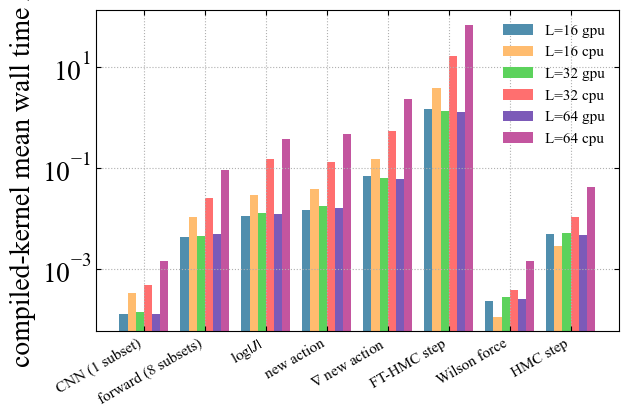

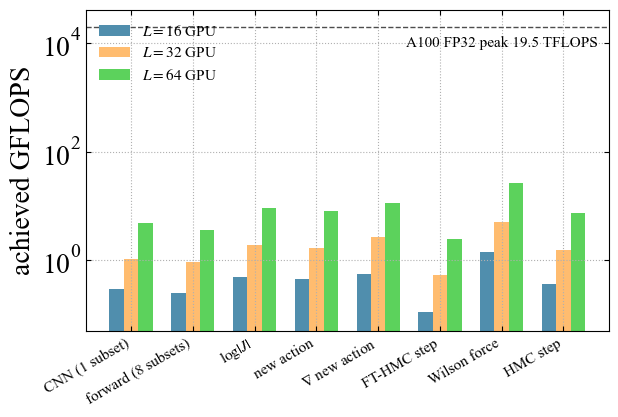

In [3]:
k_header = ["kernel"] + [f"L{lattice} {device.upper()} / s" for lattice in LATTICES for device in DEVICES]
k_lines = [
    "## Compiled-kernel mean wall time (AOT replay)",
    "",
    "| " + " | ".join(k_header) + " |",
    "|" + "|".join(["---"] + ["---:" for _ in k_header[1:]]) + "|",
]
for name in KERNEL_ORDER:
    vals = [fmt(kernel_mean(dumps[(lattice, device)], name), ".4f") for lattice in LATTICES for device in DEVICES]
    label = KERNEL_LABELS[name].replace("|", r"\|")
    k_lines.append("| " + " | ".join([label] + vals) + " |")
display(Markdown("\n".join(k_lines)))

last_L = LATTICES[-1]
u_header = [
    "kernel",
    *[f"L{lattice} GFLOPS" for lattice in LATTICES],
    f"L{last_L} % of 19.5 TFLOPS",
    f"L{last_L} GB/s",
    f"L{last_L} % of 1555 GB/s",
]
u_lines = [
    "## GPU achieved throughput vs 1×A100 peak",
    "",
    "XLA FLOPs / AOT wall time on **GPU only**. Peak is advertised A100-40GB FP32 (19.5 TFLOPS) and HBM2 (1555 GB/s).",
    "",
    "| " + " | ".join(u_header) + " |",
    "|" + "|".join(["---"] + ["---:" for _ in u_header[1:]]) + "|",
]
for name in KERNEL_ORDER:
    gflops = [kernel_gflops(dumps[(lattice, "gpu")], name) for lattice in LATTICES]
    gbs_last = kernel_gbs(dumps[(last_L, "gpu")], name)
    label = KERNEL_LABELS[name].replace("|", r"\|")
    u_lines.append(
        "| "
        + " | ".join(
            [
                label,
                *[fmt_gflops(value) for value in gflops],
                fmt_pct(pct_peak_fp32(gflops[-1])),
                fmt(gbs_last, ".2f"),
                fmt_pct(pct_peak_hbm(gbs_last)),
            ]
        )
        + " |"
    )
display(Markdown("\n".join(u_lines)))

ready_kernels = any(dumps[(lattice, device)] is not None for lattice in LATTICES for device in DEVICES)
if ready_kernels:
    labels = [KERNEL_LABELS[name] for name in KERNEL_ORDER]
    x = np.arange(len(labels))
    n_series = len(LATTICES) * len(DEVICES)
    width = 0.8 / n_series
    fig, ax = default_plot()
    offset = -0.5 * (n_series - 1) * width
    color_i = 0
    for lattice in LATTICES:
        for device in DEVICES:
            values = [kernel_mean(dumps[(lattice, device)], name) for name in KERNEL_ORDER]
            values = [np.nan if value is None else value for value in values]
            ax.bar(x + offset, values, width=width, label=f"L={lattice} {device}", color=color_ls[color_i])
            offset += width
            color_i += 1
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.tick_params(axis="x", labelsize=11)
    ax.set_ylabel(r"compiled-kernel mean wall time / s", **fs_p)
    ax.set_yscale("log")
    ax.legend(frameon=False, fontsize=11)
    fig.savefig(PLOT_DIR / "cpu_gpu_kernel_times.pdf", transparent=True, bbox_inches="tight")
    plt.show()

    fig, ax = default_plot()
    n_gpu = len(LATTICES)
    width = 0.7 / n_gpu
    offset = -0.5 * (n_gpu - 1) * width
    for i, lattice in enumerate(LATTICES):
        values = [kernel_gflops(dumps[(lattice, "gpu")], name) for name in KERNEL_ORDER]
        values = [np.nan if value is None else value for value in values]
        ax.bar(x + offset, values, width=width, label=fr"$L={lattice}$ GPU", color=color_ls[i])
        offset += width
    ax.axhline(A100_FP32_GFLOPS, color="0.3", linestyle="--", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.tick_params(axis="x", labelsize=11)
    ax.set_ylabel(r"achieved GFLOPS", **fs_p)
    ax.set_yscale("log")
    ax.set_ylim(5e-2, 4e4)
    ax.legend(frameon=False, fontsize=11, loc="upper left")
    ax.text(
        0.98,
        0.92,
        "A100 FP32 peak 19.5 TFLOPS",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=11,
    )
    fig.savefig(PLOT_DIR / "cpu_gpu_gflops.pdf", transparent=True, bbox_inches="tight")
    plt.show()
else:
    display(Markdown("No dumps yet; kernel figure skipped."))


## Projected 2048-config totals

Projection uses the profiled first-step compile, then 199 therm steps each with therm extras (`forward` + plaquette, no $Q$), then 2048 run steps each with **Python extras** (`forward` + plaquette + $Q$). Same $n_{\mathrm{therm}}=200$, $n_{\mathrm{configs}}=2048$ for every $L$.

**What the table shows.** These are the **baseline** (unjitted extras) dumps. GPU stays **$3.88 / 3.78 / 3.84$ h** at L16/L32/L64: extras lock the production cost near $6$ s/config. CPU is **$5.71 / 13.5 / 48.7$ h**. GPU/CPU projected total falls from $0.68$ to $0.28$ to **$0.08$** only because the CPU compiled step grew; the GPU wall clock did not drop. Speeding up the A100 `metropolis_step` would not move this baseline GPU total; that is the point of compiling extras in the last section.

## Projected production totals

| L | GPU / h | CPU / h | GPU/CPU |
|---:|---:|---:|---:|
| 16 | 3.88 | 5.71 | 0.68 |
| 32 | 3.78 | 13.50 | 0.28 |
| 64 | 3.84 | 48.72 | 0.08 |

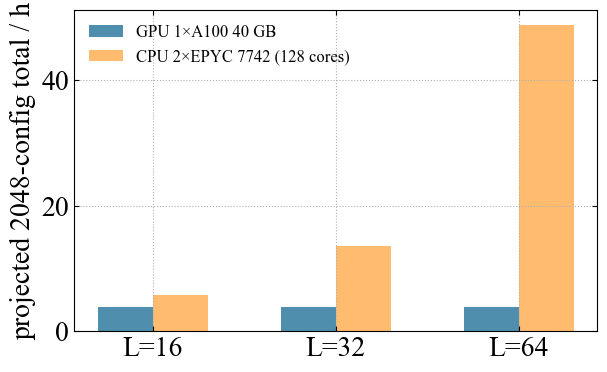

In [4]:
p_lines = ["## Projected production totals", "", "| L | GPU / h | CPU / h | GPU/CPU |", "|---:|---:|---:|---:|"]
totals = {}
for lattice in LATTICES:
    gpu_h = wall(dumps[(lattice, "gpu")])["projected_h"]
    cpu_h = wall(dumps[(lattice, "cpu")])["projected_h"]
    totals[lattice] = (gpu_h, cpu_h)
    ratio = None if gpu_h is None or cpu_h in {None, 0} else gpu_h / cpu_h
    p_lines.append(f"| {lattice} | {fmt(gpu_h, '.2f')} | {fmt(cpu_h, '.2f')} | {fmt(ratio, '.2f')} |")
display(Markdown("\n".join(p_lines)))

if any(value is not None for pair in totals.values() for value in pair):
    fig, ax = default_plot()
    x = np.arange(len(LATTICES))
    gpu_vals = [totals[lattice][0] if totals[lattice][0] is not None else np.nan for lattice in LATTICES]
    cpu_vals = [totals[lattice][1] if totals[lattice][1] is not None else np.nan for lattice in LATTICES]
    ax.bar(x - 0.15, gpu_vals, width=0.3, label=GPU_LABEL, color=color_ls[0])
    ax.bar(x + 0.15, cpu_vals, width=0.3, label=CPU_LABEL, color=color_ls[1])
    ax.set_xticks(x)
    ax.set_xticklabels([f"L={lattice}" for lattice in LATTICES])
    ax.set_ylabel(r"projected 2048-config total / h", **fs_p)
    ax.legend(frameon=False, fontsize=12)
    fig.savefig(PLOT_DIR / "cpu_gpu_projected_total.pdf", transparent=True, bbox_inches="tight")
    plt.show()
else:
    display(Markdown("No dumps yet; projected-total figure skipped."))

## Scaling

GPU/CPU is the projected-total ratio at each $L$. Consecutive $L$ ratios (L32/L16, L64/L32) are how each backend grows when the volume increases by $4\times$. The dashed line on the figure is that $4\times$ FLOP / volume factor.

**GPU stays flat through L64.** FT-step ratios are $0.95$ then $0.95$; projected totals $0.97$ then $1.02$. The ~$5\%$ L16-to-L32 drop is larger than the $0.4\%$ step std, so it is a real job-to-job difference (different nodes, clocks, XLA fusion), not sampling noise, and it is **not** volume scaling. FLOPs scaled ~$4.4\times$ per doubling; wall time did not. $16^2$, $32^2$, and $64^2$ are all tiny versus 6912 CUDA cores, so the compiled step is still launch/remat latency.

**CPU compiled work tracks volume.** FT-step ratios are $4.18$ then $4.42$. Projected-total ratios are smaller ($2.36$ then $3.61$) because Python extras stay ~$4.2$ s and dilute the average. At L16 extras $\approx$ the compiled step, so the $4\times$ step growth only doubles the config cost; at L64 extras are ~$6\%$ of the $77$ s loop and the projected ratio is catching up to $4\times$. HMC on CPU follows the same pattern ($3.59$ then $4.13$).

**GPU vs CPU therefore widens with $L$ for the wrong reason.** The compiled FT-step GPU/CPU ratio goes $0.36\to 0.08\to 0.02$, and the projected total $0.68\to 0.28\to 0.08$, because CPU time grew. The GPU production path in these baseline dumps is still host-Python bound. Compiling the extras is the next section.

## Device and volume ratios

- L=16 GPU/CPU projected total: **0.68**
- L=32 GPU/CPU projected total: **0.28**
- L=64 GPU/CPU projected total: **0.08**
- GPU L32/L16: **0.97**
- CPU L32/L16: **2.36**
- GPU L64/L32: **1.02**
- CPU L64/L32: **3.61**

| metric | L16 GPU/CPU | L32 GPU/CPU | L64 GPU/CPU | GPU L32/L16 | CPU L32/L16 | GPU L64/L32 | CPU L64/L32 |
|---|---:|---:|---:|---:|---:|---:|---:|
| FT compile | 0.20 | 0.21 | 0.22 | 1.04 | 0.98 | 1.04 | 1.00 |
| FT step | 0.36 | 0.08 | 0.02 | 0.95 | 4.18 | 0.95 | 4.42 |
| Python extras | 1.11 | 1.08 | 1.05 | 0.98 | 1.01 | 1.03 | 1.06 |
| HMC step | 1.78 | 0.52 | 0.11 | 1.04 | 3.59 | 0.89 | 4.13 |
| projected total | 0.68 | 0.28 | 0.08 | 0.97 | 2.36 | 1.02 | 3.61 |

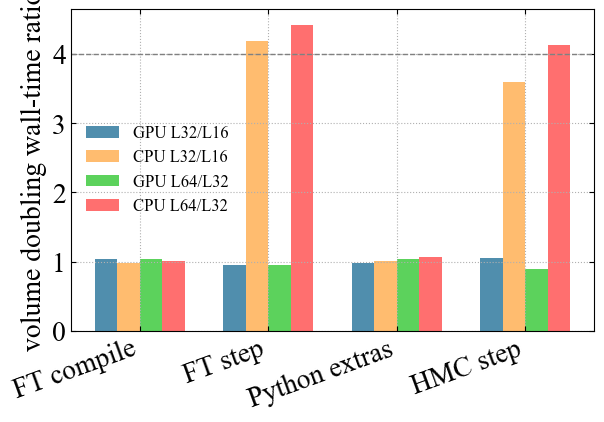

In [5]:
def ratio(num, den):
    if num is None or den in {None, 0}:
        return None
    return num / den


volume_pairs = [
    (small, large)
    for small, large in zip(LATTICES[:-1], LATTICES[1:])
]

s_lines = ["## Device and volume ratios", ""]
for lattice in LATTICES:
    gpu_h, cpu_h = totals[lattice]
    s_lines.append(f"- L={lattice} GPU/CPU projected total: **{fmt(ratio(gpu_h, cpu_h), '.2f')}**")
for small, large in volume_pairs:
    gpu_small, cpu_small = totals[small]
    gpu_large, cpu_large = totals[large]
    s_lines.append(f"- GPU L{large}/L{small}: **{fmt(ratio(gpu_large, gpu_small), '.2f')}**")
    s_lines.append(f"- CPU L{large}/L{small}: **{fmt(ratio(cpu_large, cpu_small), '.2f')}**")

metric_cols = [f"L{lattice} GPU/CPU" for lattice in LATTICES]
for small, large in volume_pairs:
    metric_cols.extend([f"GPU L{large}/L{small}", f"CPU L{large}/L{small}"])
step_lines = [
    "",
    "| metric | " + " | ".join(metric_cols) + " |",
    "|" + "|".join(["---"] + ["---:" for _ in metric_cols]) + "|",
]
for key, label in STEP_KEYS + [("projected_h", "projected total")]:
    cells = []
    for lattice in LATTICES:
        gpu_v = wall(dumps[(lattice, "gpu")])[key]
        cpu_v = wall(dumps[(lattice, "cpu")])[key]
        cells.append(fmt(ratio(gpu_v, cpu_v), ".2f"))
    for small, large in volume_pairs:
        for device in DEVICES:
            num = wall(dumps[(large, device)])[key]
            den = wall(dumps[(small, device)])[key]
            cells.append(fmt(ratio(num, den), ".2f"))
    step_lines.append("| " + " | ".join([label] + cells) + " |")
display(Markdown("\n".join(s_lines + step_lines)))

scale_series = []
color_i = 0
for small, large in volume_pairs:
    for device in DEVICES:
        have_pair = dumps[(small, device)] is not None and dumps[(large, device)] is not None
        if not have_pair:
            continue
        values = [
            ratio(wall(dumps[(large, device)])[key], wall(dumps[(small, device)])[key])
            for key, _ in STEP_KEYS
        ]
        scale_series.append((f"{device.upper()} L{large}/L{small}", values, color_ls[color_i]))
        color_i += 1

if scale_series:
    fig, ax = default_plot()
    labels = [label for _, label in STEP_KEYS]
    x = np.arange(len(labels))
    n_series = len(scale_series)
    width = 0.7 / n_series
    offset = -0.5 * (n_series - 1) * width
    for name, values, color in scale_series:
        plotted = [np.nan if value is None else value for value in values]
        ax.bar(x + offset, plotted, width=width, label=name, color=color)
        offset += width
    ax.axhline(4.0, color="0.5", linestyle="--", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=20, ha="right")
    ax.set_ylabel(r"volume doubling wall-time ratio", **fs_p)
    ax.legend(frameon=False, fontsize=12)
    fig.savefig(PLOT_DIR / "cpu_gpu_volume_scaling.pdf", transparent=True, bbox_inches="tight")
    plt.show()
else:
    display(Markdown("Need a consecutive pair (L16+L32, or L32+L64) on a device before the scaling figure."))


## Compiled extras (`dump_suffix=jitobs`)

The tables above are the unjitted-extras baseline, including the CPU comparison. This extras-JIT check is **GPU only**, at L16/L32/L64.

Production `HMCU2FT.thermalize` / `run` now call jitted `therm_observables` and `run_observables` (`forward` + plaquette, plus $Q$ in the run phase). Inverse is still the training `while_loop` and is not in this eval path.

GPU profiles were submitted with `DUMP_SUFFIX=jitobs` so they do not overwrite the baseline dumps: PBS 185109 (L16), 185114 (L32), 185115 (L64). Re-run this cell when those JSON files land. If extras collapse to the compiled `forward` (~5 ms) plus a cheap `float()` sync, the GPU loop should sit near the FT step (~1.3 s) and the 2048-config projection near **0.9 h** versus the baseline ~3.8 h.

The remaining GPU bound after extras compile is the compiled Omelyan step itself: 21 rematerialized `force` launches, ~1.3 s, still $\ll 1\%$ of A100 FP32 peak.

## GPU extras JIT: L16 / L32 / L64

| L | extras before / s | extras after / s | after/before | loop before / s | loop after / s | projected before / h | projected after / h |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 16 | 4.5581 | 0.0044 | 0.001 | 5.9782 | 1.4252 | 3.88 | 1.03 |
| 32 | 4.4607 | 0.0045 | 0.001 | 5.8074 | 1.3423 | 3.78 | 0.98 |
| 64 | 4.6098 | 0.0049 | 0.001 | 5.8854 | 1.3211 | 3.84 | 0.97 |

**Readout.**

- L=16 GPU: extras 4.558 s → 0.0044 s (after/before **0.001**); loop 5.978 s → 1.425 s (**0.238**); projected 3.88 h → 1.03 h (**0.264**).
- L=32 GPU: extras 4.461 s → 0.0045 s (after/before **0.001**); loop 5.807 s → 1.342 s (**0.231**); projected 3.78 h → 0.98 h (**0.258**).
- L=64 GPU: extras 4.610 s → 0.0049 s (after/before **0.001**); loop 5.885 s → 1.321 s (**0.224**); projected 3.84 h → 0.97 h (**0.252**).
- After extras JIT, the L16 GPU production cost is the compiled FT step plus leftover extras (1.421 + 0.0044 s). The next GPU bound is the 21 remat `force` launches inside `metropolis_step`, not host Python.

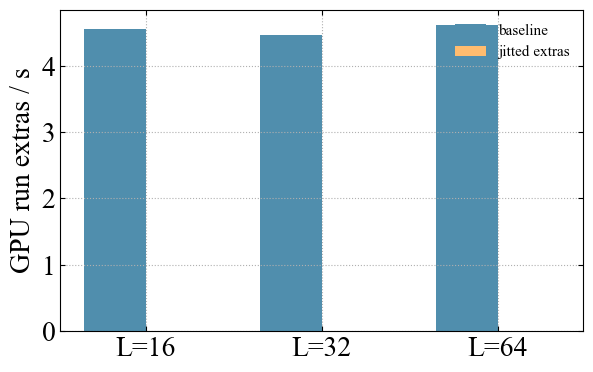

In [6]:
def ratio(before, after):
    if before is None or after in {None, 0}:
        return None
    return after / before


j_lines = [
    "## GPU extras JIT: L16 / L32 / L64",
    "",
    "| L | extras before / s | extras after / s | after/before | loop before / s | loop after / s | projected before / h | projected after / h |",
    "|---:|---:|---:|---:|---:|---:|---:|---:|",
]
have_jitobs = False
for lattice in LATTICES:
    before = wall(dumps[(lattice, "gpu")])
    after_dump = jitobs_dumps[lattice]
    after = wall(after_dump)
    have_jitobs = have_jitobs or after_dump is not None
    j_lines.append(
        f"| {lattice} | {fmt(before['extras'], '.4f')} | {fmt(after['extras'], '.4f')} | "
        f"{fmt(ratio(before['extras'], after['extras']), '.3f')} | {fmt(before['loop'], '.4f')} | "
        f"{fmt(after['loop'], '.4f')} | {fmt(before['projected_h'], '.2f')} | {fmt(after['projected_h'], '.2f')} |"
    )
display(Markdown("\n".join(j_lines)))

notes = []
for lattice in LATTICES:
    before = wall(dumps[(lattice, "gpu")])
    after = wall(jitobs_dumps[lattice])
    if jitobs_dumps[lattice] is None:
        notes.append(f"- L={lattice} GPU jitobs dump is missing.")
        continue
    extras_r = ratio(before["extras"], after["extras"])
    loop_r = ratio(before["loop"], after["loop"])
    proj_r = ratio(before["projected_h"], after["projected_h"])
    notes.append(
        f"- L={lattice} GPU: extras {fmt(before['extras'], '.3f')} s → {fmt(after['extras'], '.4f')} s "
        f"(after/before **{fmt(extras_r, '.3f')}**); loop {fmt(before['loop'], '.3f')} s → "
        f"{fmt(after['loop'], '.3f')} s (**{fmt(loop_r, '.3f')}**); projected "
        f"{fmt(before['projected_h'], '.2f')} h → {fmt(after['projected_h'], '.2f')} h "
        f"(**{fmt(proj_r, '.3f')}**)."
    )
if not have_jitobs:
    notes.append(
        "- No GPU `jitobs` dumps on disk yet (PBS 185109 L16, 185114 L32, 185115 L64). "
        "Re-run this cell after those jobs finish."
    )
else:
    gpu_after = wall(jitobs_dumps[16])
    if gpu_after["loop"] is not None:
        notes.append(
            f"- After extras JIT, the L16 GPU production cost is the compiled FT step plus leftover extras "
            f"({fmt(gpu_after['steady'], '.3f')} + {fmt(gpu_after['extras'], '.4f')} s). "
            "The next GPU bound is the 21 remat `force` launches inside `metropolis_step`, not host Python."
        )
display(Markdown("\n".join(["**Readout.**", ""] + notes)))

plot_l = [lattice for lattice in LATTICES if dumps[(lattice, "gpu")] is not None and jitobs_dumps[lattice] is not None]
if plot_l:
    fig, ax = default_plot()
    x = np.arange(len(plot_l))
    width = 0.35
    before_vals = [wall(dumps[(lattice, "gpu")])["extras"] for lattice in plot_l]
    after_vals = [wall(jitobs_dumps[lattice])["extras"] for lattice in plot_l]
    ax.bar(x - width / 2, before_vals, width=width, label="baseline", color=color_ls[0])
    ax.bar(x + width / 2, after_vals, width=width, label="jitted extras", color=color_ls[1])
    ax.set_xticks(x)
    ax.set_xticklabels([f"L={lattice}" for lattice in plot_l])
    ax.set_ylabel(r"GPU run extras / s", **fs_p)
    ax.legend(frameon=False, fontsize=11)
    fig.savefig(PLOT_DIR / "cpu_gpu_extras_jit.pdf", transparent=True, bbox_inches="tight")
    plt.show()
else:
    display(Markdown("No paired baseline/`jitobs` GPU dumps yet; extras comparison figure skipped."))

## Caveats

- Totals are **projections** from 32 profiled steps, not a full 2048-config chain.
- GPU is production-like: **1× NVIDIA A100 40 GB**, `PREALLOCATE=false`, empty CUDA command buffers. This is not the node's 8 GPUs.
- CPU is **2× AMD EPYC 7742** (Rome): 64 cores/socket → **128 physical cores / 256 SMT threads**, **~1 TB DDR4**. JAX uses 128 OpenMP/XLA threads (`OMP_NUM_THREADS=physical_cores`), one CPU device, no chain sharding. PBS `by-node` `select=1` is how that whole DGX is charged, not a description of the CPU.
- Jobs ran on different Sophia nodes (L16 GPU dump has no hostname; L32 GPU `sophia-gpu-07`; L64 GPU `sophia-gpu-06`; CPU L16/L32/L64 on `07`/`06`/`03`). Compiled-step std is tiny; extras std is ~$1$ s (~$25\%$), so extras comparisons at the $5\%$ level are noisy.
- L32 and L64 timing use L16 `base` weights unless a native checkpoint is on disk.
- Isolated compiled kernels are attribution only; do not add them on top of `fthmc_step`. GFLOPS uses XLA `cost_analysis` FLOPs (compiler estimate) over AOT wall time; % peak is advertised A100-40GB FP32 / HBM2, not a measured `nvidia-smi` occupancy.
- The L16/L32/L64 tables above are the **unjitted-extras** baseline (GPU and CPU). Production extras are now jitted; `jitobs` dumps are GPU-only L16/L32/L64 with a separate filename suffix. After extras compile, the remaining GPU bound is the rematerialized Omelyan `force` graph (~1.3 s), not host Python.